In [1]:
from src.featurize import featurize
import pandas as pd
from pathlib import Path
import numpy as np
import os


enzyme_classes_sample = {
    "Oxidoreductases": "1.-.-.-",
    "Transferases": "2.-.-.-",
    "Hydrolases": "3.-.-.-",
    "Lyases": "4.-.-.-",
    "Isomerases": "5.-.-.-",
    "Ligases": "6.-.-.-",
    "Translocases": "7.-.-.-"
}
proj_path = Path.cwd().parent 

csv_files = os.listdir(proj_path / "data" / "RawSequences" )
csv_files = [file for file in csv_files if ".csv" in file]
all_samples = False
for ec in enzyme_classes_sample.keys():
    curr_sample = pd.read_csv(proj_path / "data" / "CleanedSequences" / f"{ec}Cleaned.csv").sample(2000,random_state=42) #Sample 2000 of the sequences
    curr_sample = featurize(curr_sample)
    curr_sample = np.append(curr_sample,np.array([[ec]*2000]).T,axis=1)
    if type(all_samples) != np.ndarray:
        all_samples = curr_sample
    else:
        all_samples = np.append(all_samples,curr_sample,axis=0)



    

In [2]:
all_samples_df = pd.DataFrame(all_samples).sample(n=len(all_samples),replace=False,random_state=42)
test,train = all_samples_df.iloc[:int((0.33*len(all_samples_df))//1),:],all_samples_df.iloc[int((0.33*len(all_samples_df))//1):,:]

In [ ]:

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(all_samples[:,:-1], all_samples[:,-1], test_size=0.33, random_state=42)




: 

: 

In [ ]:
from sklearn.svm import SVC

SVC_model = SVC(kernel="rbf",random_state=42)
SVC_model.fit(train.iloc[:,:-1].to_numpy(),train.iloc[:,-1].to_numpy())

NameError: name 'X_train' is not defined

In [3]:
from sklearn.ensemble import RandomForestClassifier

RFC_model = RandomForestClassifier(random_state=42)
RFC_model.fit(train.iloc[:,:-1].to_numpy(),train.iloc[:,-1].to_numpy())

,n_estimators,100
,criterion,'gini'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [7]:
#print(f"SVC model accuracy: {100*SVC_model.score(X_test,y_test)}%") 
print(f"Random Forest Accuracy: {100*RFC_model.score(test.iloc[:,:-1].to_numpy(),test.iloc[:,-1].to_numpy())}%")

Random Forest Accuracy: 100.0%


In [8]:
from itertools import product

features = [amino_acid for amino_acid in "ACDEFGHIKLMNPQRSTVWY"]
features.append("MW")
features.append("Flexibility")
features.append("GRAVY")
features.append("Helix")
features.append("Turn")
features.append("Sheet")
for kmer in ["".join(p) for p in product("ACDEFGHIKLMNPQRSTVWY",repeat=3)]:
    features.append(kmer)
features = np.append(np.array([features]).T,np.array([RFC_model.feature_importances_]).T,axis=1)
features = pd.DataFrame(features)
features = features.rename(columns={0:"Feature",1:"Importance"})


In [9]:

features.sort_values("Importance",ascending=False).head(20)

,Feature,Importance
2648,HND,9.951838882062619e-06
1945,FSY,9.921925284960456e-06
1356,EHM,9.921755478945856e-06
6508,TFD,9.921542291437957e-06
646,CNA,9.921269766302757e-06
4545,NGY,9.921136194036843e-06
3862,LNT,9.921065533907902e-06
2534,HGK,9.92061821278744e-06
245,AMY,9.920567175871115e-06
5882,RPT,9.818568607465311e-06


'sns.barplot(data=features,x="Importance",y="Feature",ax=ax)\nplt.plot()'

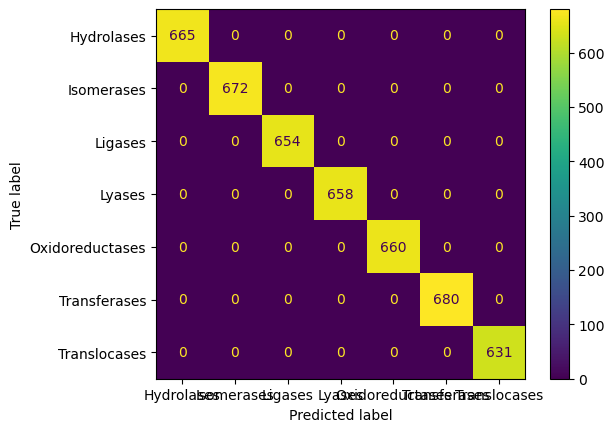

In [10]:
from sklearn.metrics import ConfusionMatrixDisplay
import seaborn as sns
import matplotlib.pyplot as plt
"""ax = plt.figure(1).add_axes([0.1,0.1,0.8,0.8])"""
ConfusionMatrixDisplay.from_estimator(RFC_model, X_test, y_test)
"""sns.barplot(data=features,x="Importance",y="Feature",ax=ax)
plt.plot()"""

In [4]:
from pickle import dump
with open(proj_path / "models" /"RandomForestClassifier.pkl","wb") as file:
    dump(RFC_model,file,protocol=5)